In [1]:

%pip install pandas numpy matplotlib seaborn


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("All libraries imported successfully!")


All libraries imported successfully!


In [5]:

# Load the raw dataset
df = pd.read_csv("retail_sales_dataset.csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())


Dataset loaded successfully!
Number of rows: 1000
Number of columns: 9


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [6]:

print("DATASET INFORMATION")
df.info()

print("\nCOLUMN NAMES")
print(df.columns.tolist())

print("\nDATA TYPES")
display(df.dtypes.to_frame("Data Type"))

print("\nSTATISTICAL SUMMARY")
display(df.describe(include="all").T)


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB

COLUMN NAMES
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

DATA TYPES


,Data Type
Transaction ID,int64
Date,object
Customer ID,object
Gender,object
Age,int64
Product Category,object
Quantity,int64
Price per Unit,int64
Total Amount,int64



STATISTICAL SUMMARY


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Transaction ID,1000.0,NaN,NaN,NaN,500.5,288.819436,1.0,250.75,500.5,750.25,1000.0
Date,1000,345,2023-05-16,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,1000,1000,CUST001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,1000,2,Female,510,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,1000.0,NaN,NaN,NaN,41.392,13.68143,18.0,29.0,42.0,53.0,64.0
Product Category,1000,3,Clothing,351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,1000.0,NaN,NaN,NaN,2.514,1.132734,1.0,1.0,3.0,4.0,4.0
Price per Unit,1000.0,NaN,NaN,NaN,179.89,189.681356,25.0,30.0,50.0,300.0,500.0
Total Amount,1000.0,NaN,NaN,NaN,456.0,559.997632,25.0,60.0,135.0,900.0,2000.0


MISSING VALUE REPORT


,Missing Values,Missing Percentage
Transaction ID,0,0.0
Date,0,0.0
Customer ID,0,0.0
Gender,0,0.0
Age,0,0.0
Product Category,0,0.0
Quantity,0,0.0
Price per Unit,0,0.0
Total Amount,0,0.0


No missing values found in the dataset!


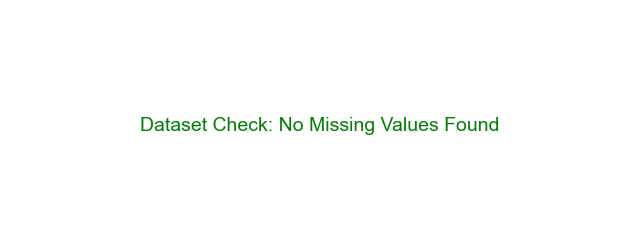

In [20]:

# Check and visualize missing values safely

missing_values = df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (
        missing_values / len(df) * 100
    ).round(2)
})

print("MISSING VALUE REPORT")
display(missing_report)

# Plot only if missing values exist
missing_only = missing_report[
    missing_report["Missing Values"] > 0
]

if not missing_only.empty:
    ax = missing_only["Missing Values"].plot(
        kind="bar",
        figsize=(9, 5),
        title="Missing Values by Column",
        color="tomato"
    )

    ax.set_ylabel("Number of Missing Values")
    ax.set_xlabel("Column Names")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

else:
    print("No missing values found in the dataset!")
    
    plt.figure(figsize=(8, 3))
    plt.text(
        0.5, 0.5,
        "Dataset Check: No Missing Values Found",
        ha="center", va="center",
        fontsize=14, color="green"
    )
    plt.axis("off")
    plt.show()


In [8]:

duplicate_count = df.duplicated().sum()

print("Duplicate rows found:", duplicate_count)

df_clean = df.drop_duplicates().copy()

print("Rows before removing duplicates:", len(df))
print("Rows after removing duplicates:", len(df_clean))


Duplicate rows found: 0
Rows before removing duplicates: 1000
Rows after removing duplicates: 1000


In [9]:

for col in df_clean.columns:
    if df_clean[col].isnull().any():
        if pd.api.types.is_numeric_dtype(df_clean[col]):
            df_clean[col] = df_clean[col].fillna(
                df_clean[col].median()
            )
        else:
            mode_values = df_clean[col].mode()
            if not mode_values.empty:
                df_clean[col] = df_clean[col].fillna(
                    mode_values.iloc[0]
                )
            else:
                df_clean[col] = df_clean[col].fillna("Unknown")

print("Missing values handled.")
print("\nRemaining missing values:")
display(df_clean.isnull().sum().to_frame("Missing Values"))


Missing values handled.

Remaining missing values:


,Missing Values
Transaction ID,0
Date,0
Customer ID,0
Gender,0
Age,0
Product Category,0
Quantity,0
Price per Unit,0
Total Amount,0


In [10]:

for col in df_clean.columns:
    if col.strip().lower() in ["date", "transaction date"]:
        df_clean[col] = pd.to_datetime(
            df_clean[col], errors="coerce"
        )

print("Data types after conversion:")
display(df_clean.dtypes.to_frame("Data Type"))


Data types after conversion:


,Data Type
Transaction ID,int64
Date,datetime64[ns]
Customer ID,object
Gender,object
Age,int64
Product Category,object
Quantity,int64
Price per Unit,int64
Total Amount,int64


In [11]:

numeric_cols = df_clean.select_dtypes(include=np.number).columns

outlier_counts = {}

for col in numeric_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    count = (
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ).sum()

    outlier_counts[col] = count

outlier_report = pd.DataFrame.from_dict(
    outlier_counts, orient="index", columns=["Potential Outliers"]
)

display(outlier_report)


,Potential Outliers
Transaction ID,0
Age,0
Quantity,0
Price per Unit,0
Total Amount,0


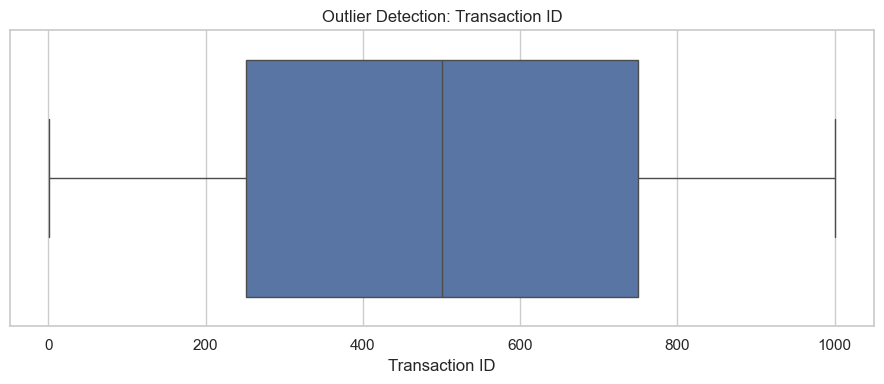

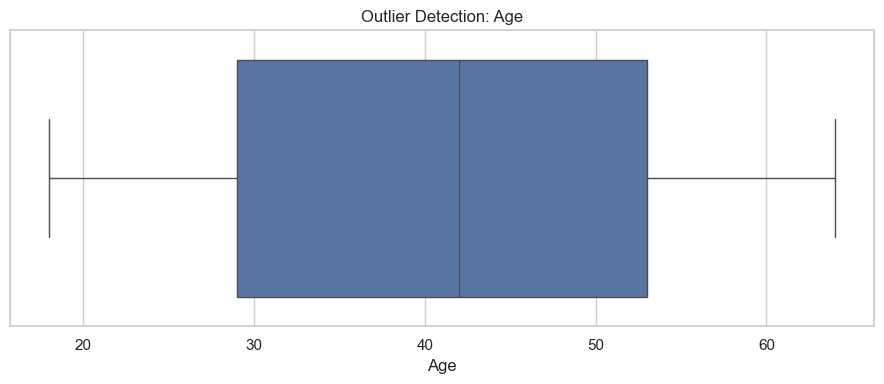

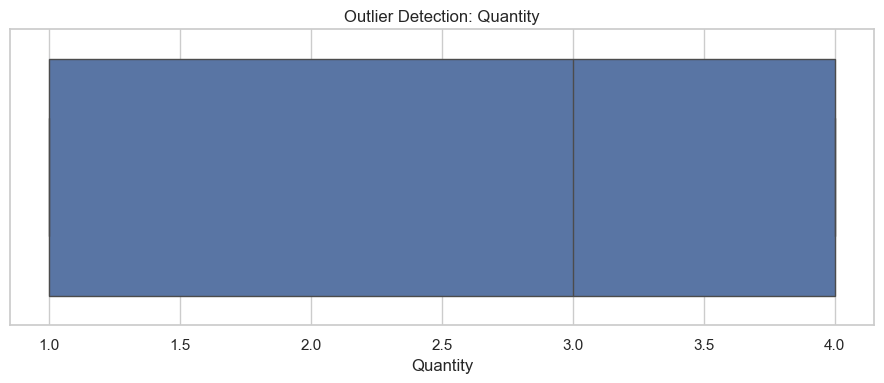

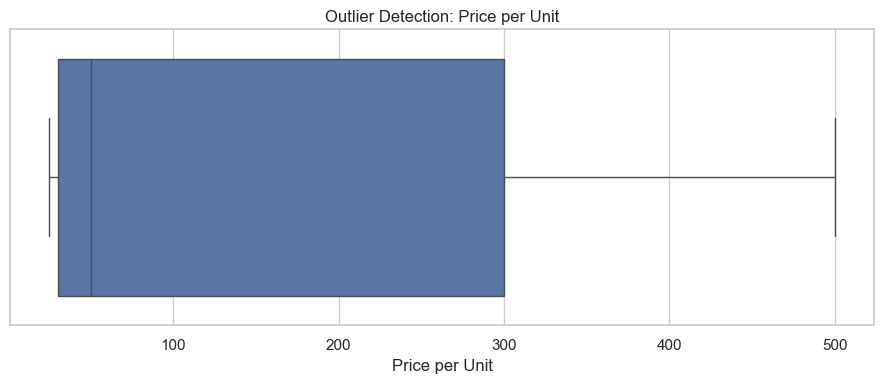

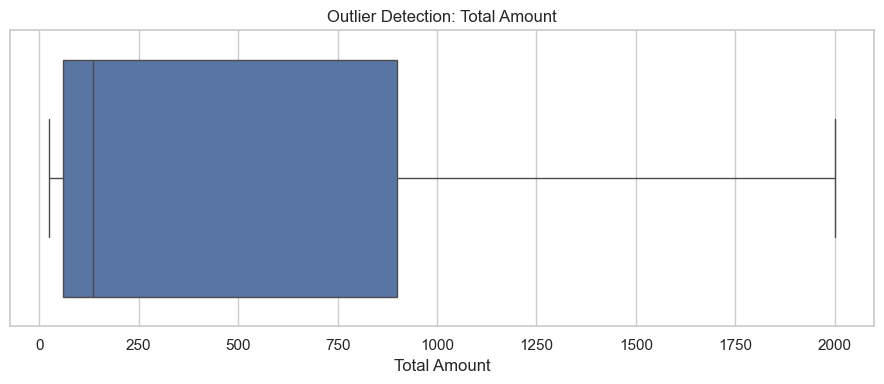

In [12]:

for col in numeric_cols:
    plt.figure(figsize=(9, 4))
    sns.boxplot(x=df_clean[col])
    plt.title(f"Outlier Detection: {col}")
    plt.tight_layout()
    plt.show()


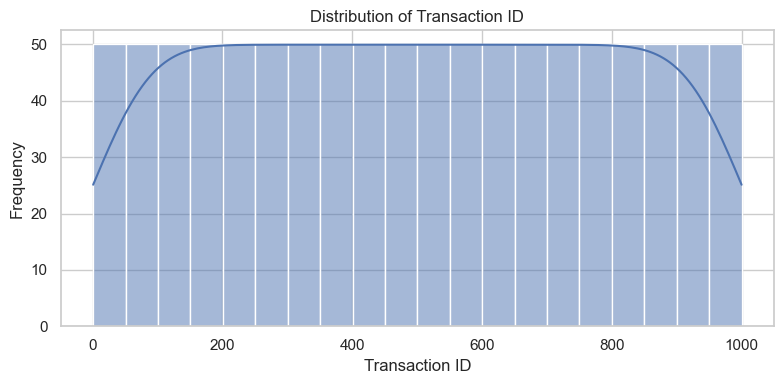

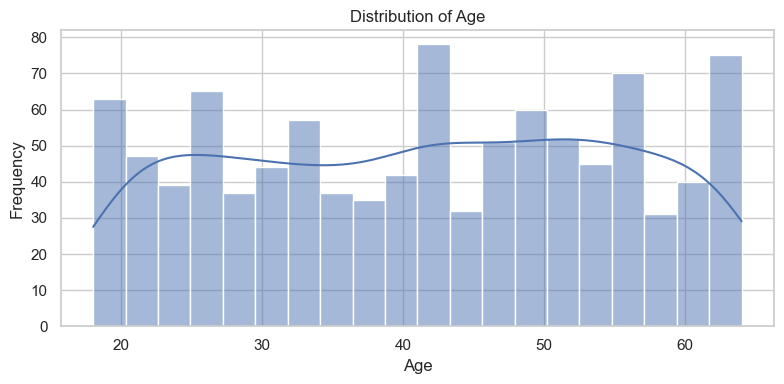

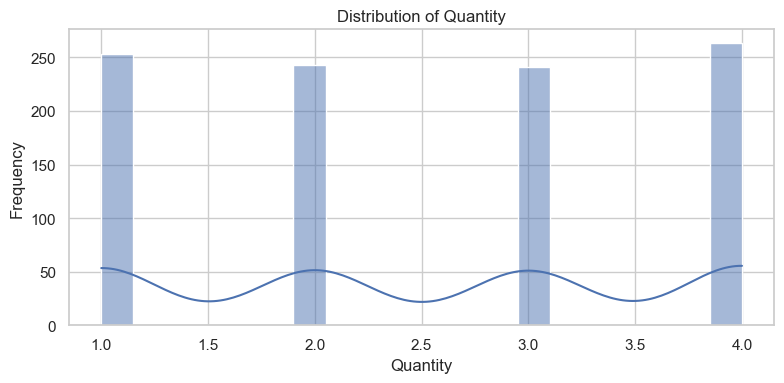

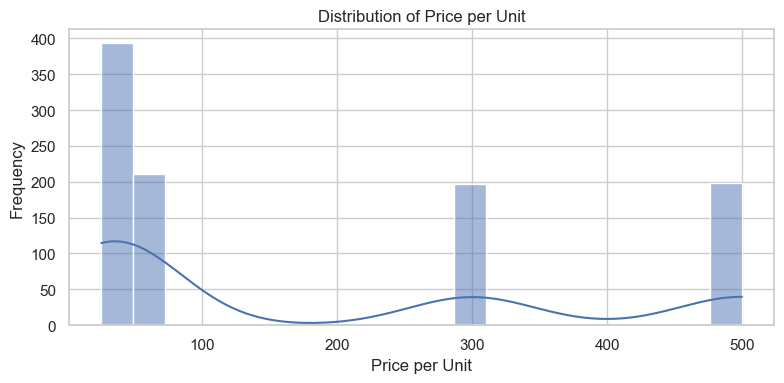

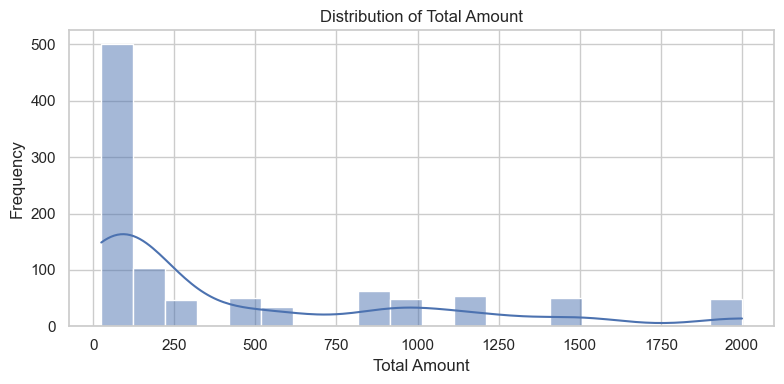

In [13]:

for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(df_clean[col].dropna(), kde=True, bins=20)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


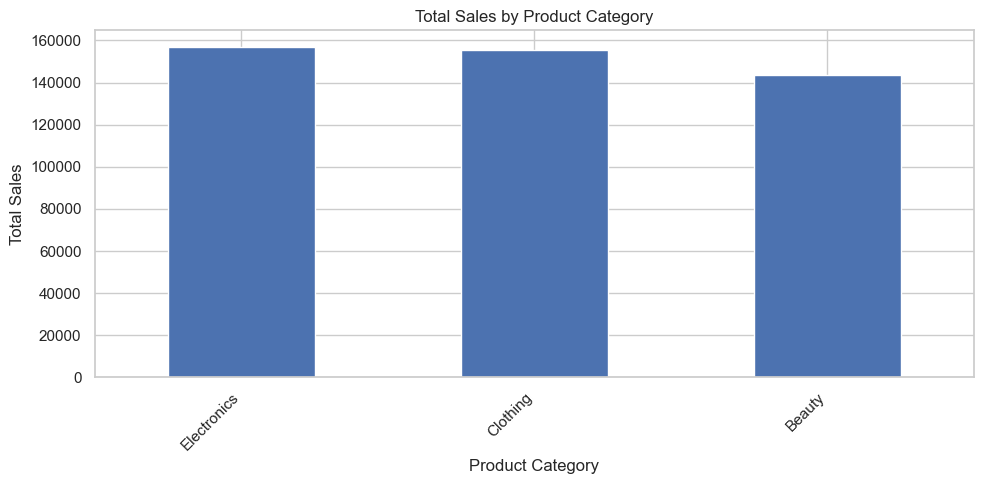

In [14]:

if {"Product Category", "Total Amount"}.issubset(df_clean.columns):
    category_sales = df_clean.groupby(
        "Product Category"
    )["Total Amount"].sum().sort_values(ascending=False)

    category_sales.plot(kind="bar", figsize=(10, 5))
    plt.title("Total Sales by Product Category")
    plt.xlabel("Product Category")
    plt.ylabel("Total Sales")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Required columns are not available.")


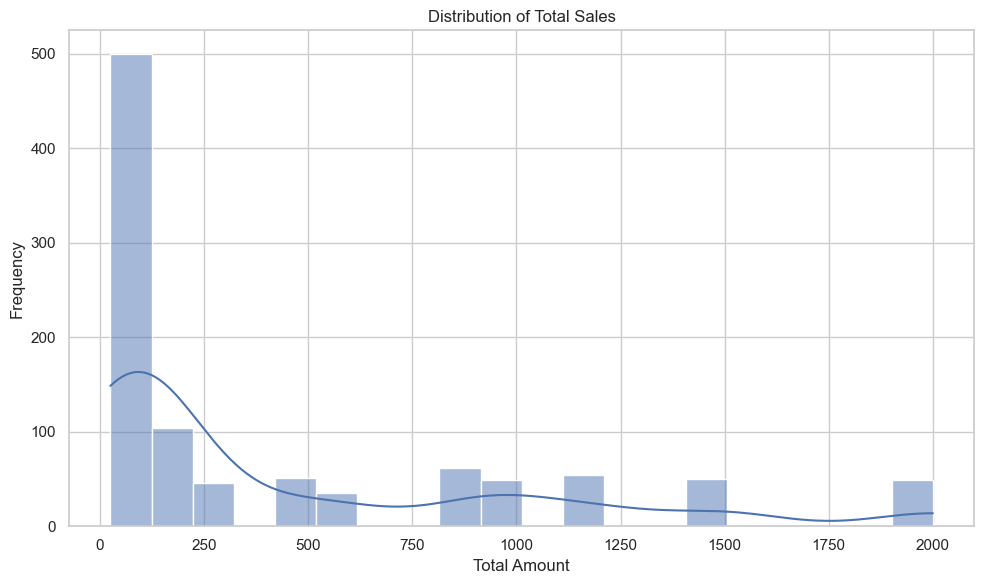

In [15]:

if "Total Amount" in df_clean.columns:
    sns.histplot(
        df_clean["Total Amount"].dropna(),
        bins=20,
        kde=True
    )
    plt.title("Distribution of Total Sales")
    plt.xlabel("Total Amount")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


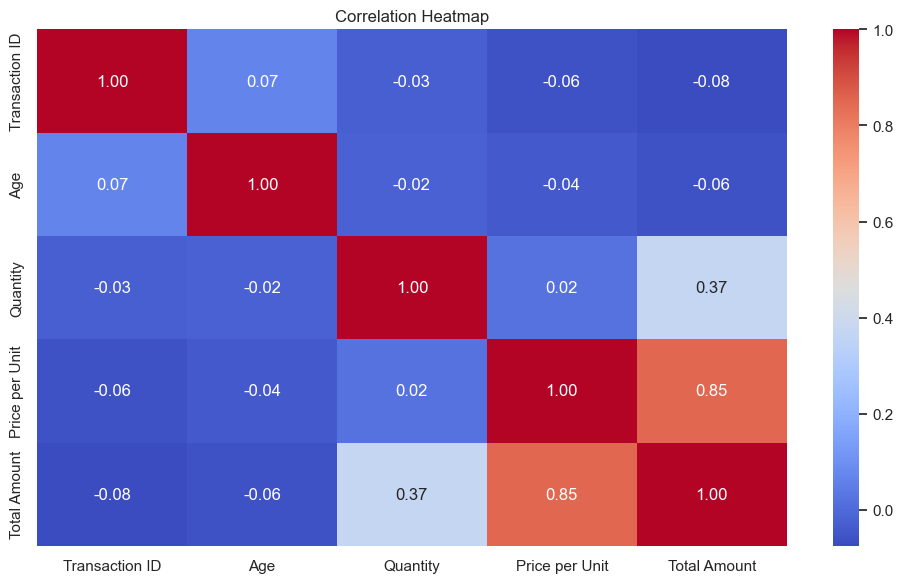

In [16]:

if len(numeric_cols) >= 2:
    correlation = df_clean[numeric_cols].corr()

    sns.heatmap(
        correlation,
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )

    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()
else:
    print("At least two numerical columns are needed.")


In [17]:

output_file = "cleaned_dataset.csv"

df_clean.to_csv(output_file, index=False)

print("Cleaned dataset saved successfully!")
print("Output file:", output_file)
print("Final number of rows:", len(df_clean))
print("Final number of columns:", len(df_clean.columns))


Cleaned dataset saved successfully!
Output file: cleaned_dataset.csv
Final number of rows: 1000
Final number of columns: 9


In [18]:

summary = pd.DataFrame({
    "Metric": [
        "Original Rows",
        "Original Columns",
        "Duplicate Rows Removed",
        "Final Rows",
        "Final Columns",
        "Remaining Missing Values",
        "Potential Outliers Detected"
    ],
    "Value": [
        len(df),
        len(df.columns),
        duplicate_count,
        len(df_clean),
        len(df_clean.columns),
        int(df_clean.isnull().sum().sum()),
        int(sum(outlier_counts.values()))
    ]
})

display(summary)

summary.to_csv("project_summary.csv", index=False)
print("Project summary saved successfully!")


,Metric,Value
0,Original Rows,1000
1,Original Columns,9
2,Duplicate Rows Removed,0
3,Final Rows,1000
4,Final Columns,9
5,Remaining Missing Values,0
6,Potential Outliers Detected,0


Project summary saved successfully!


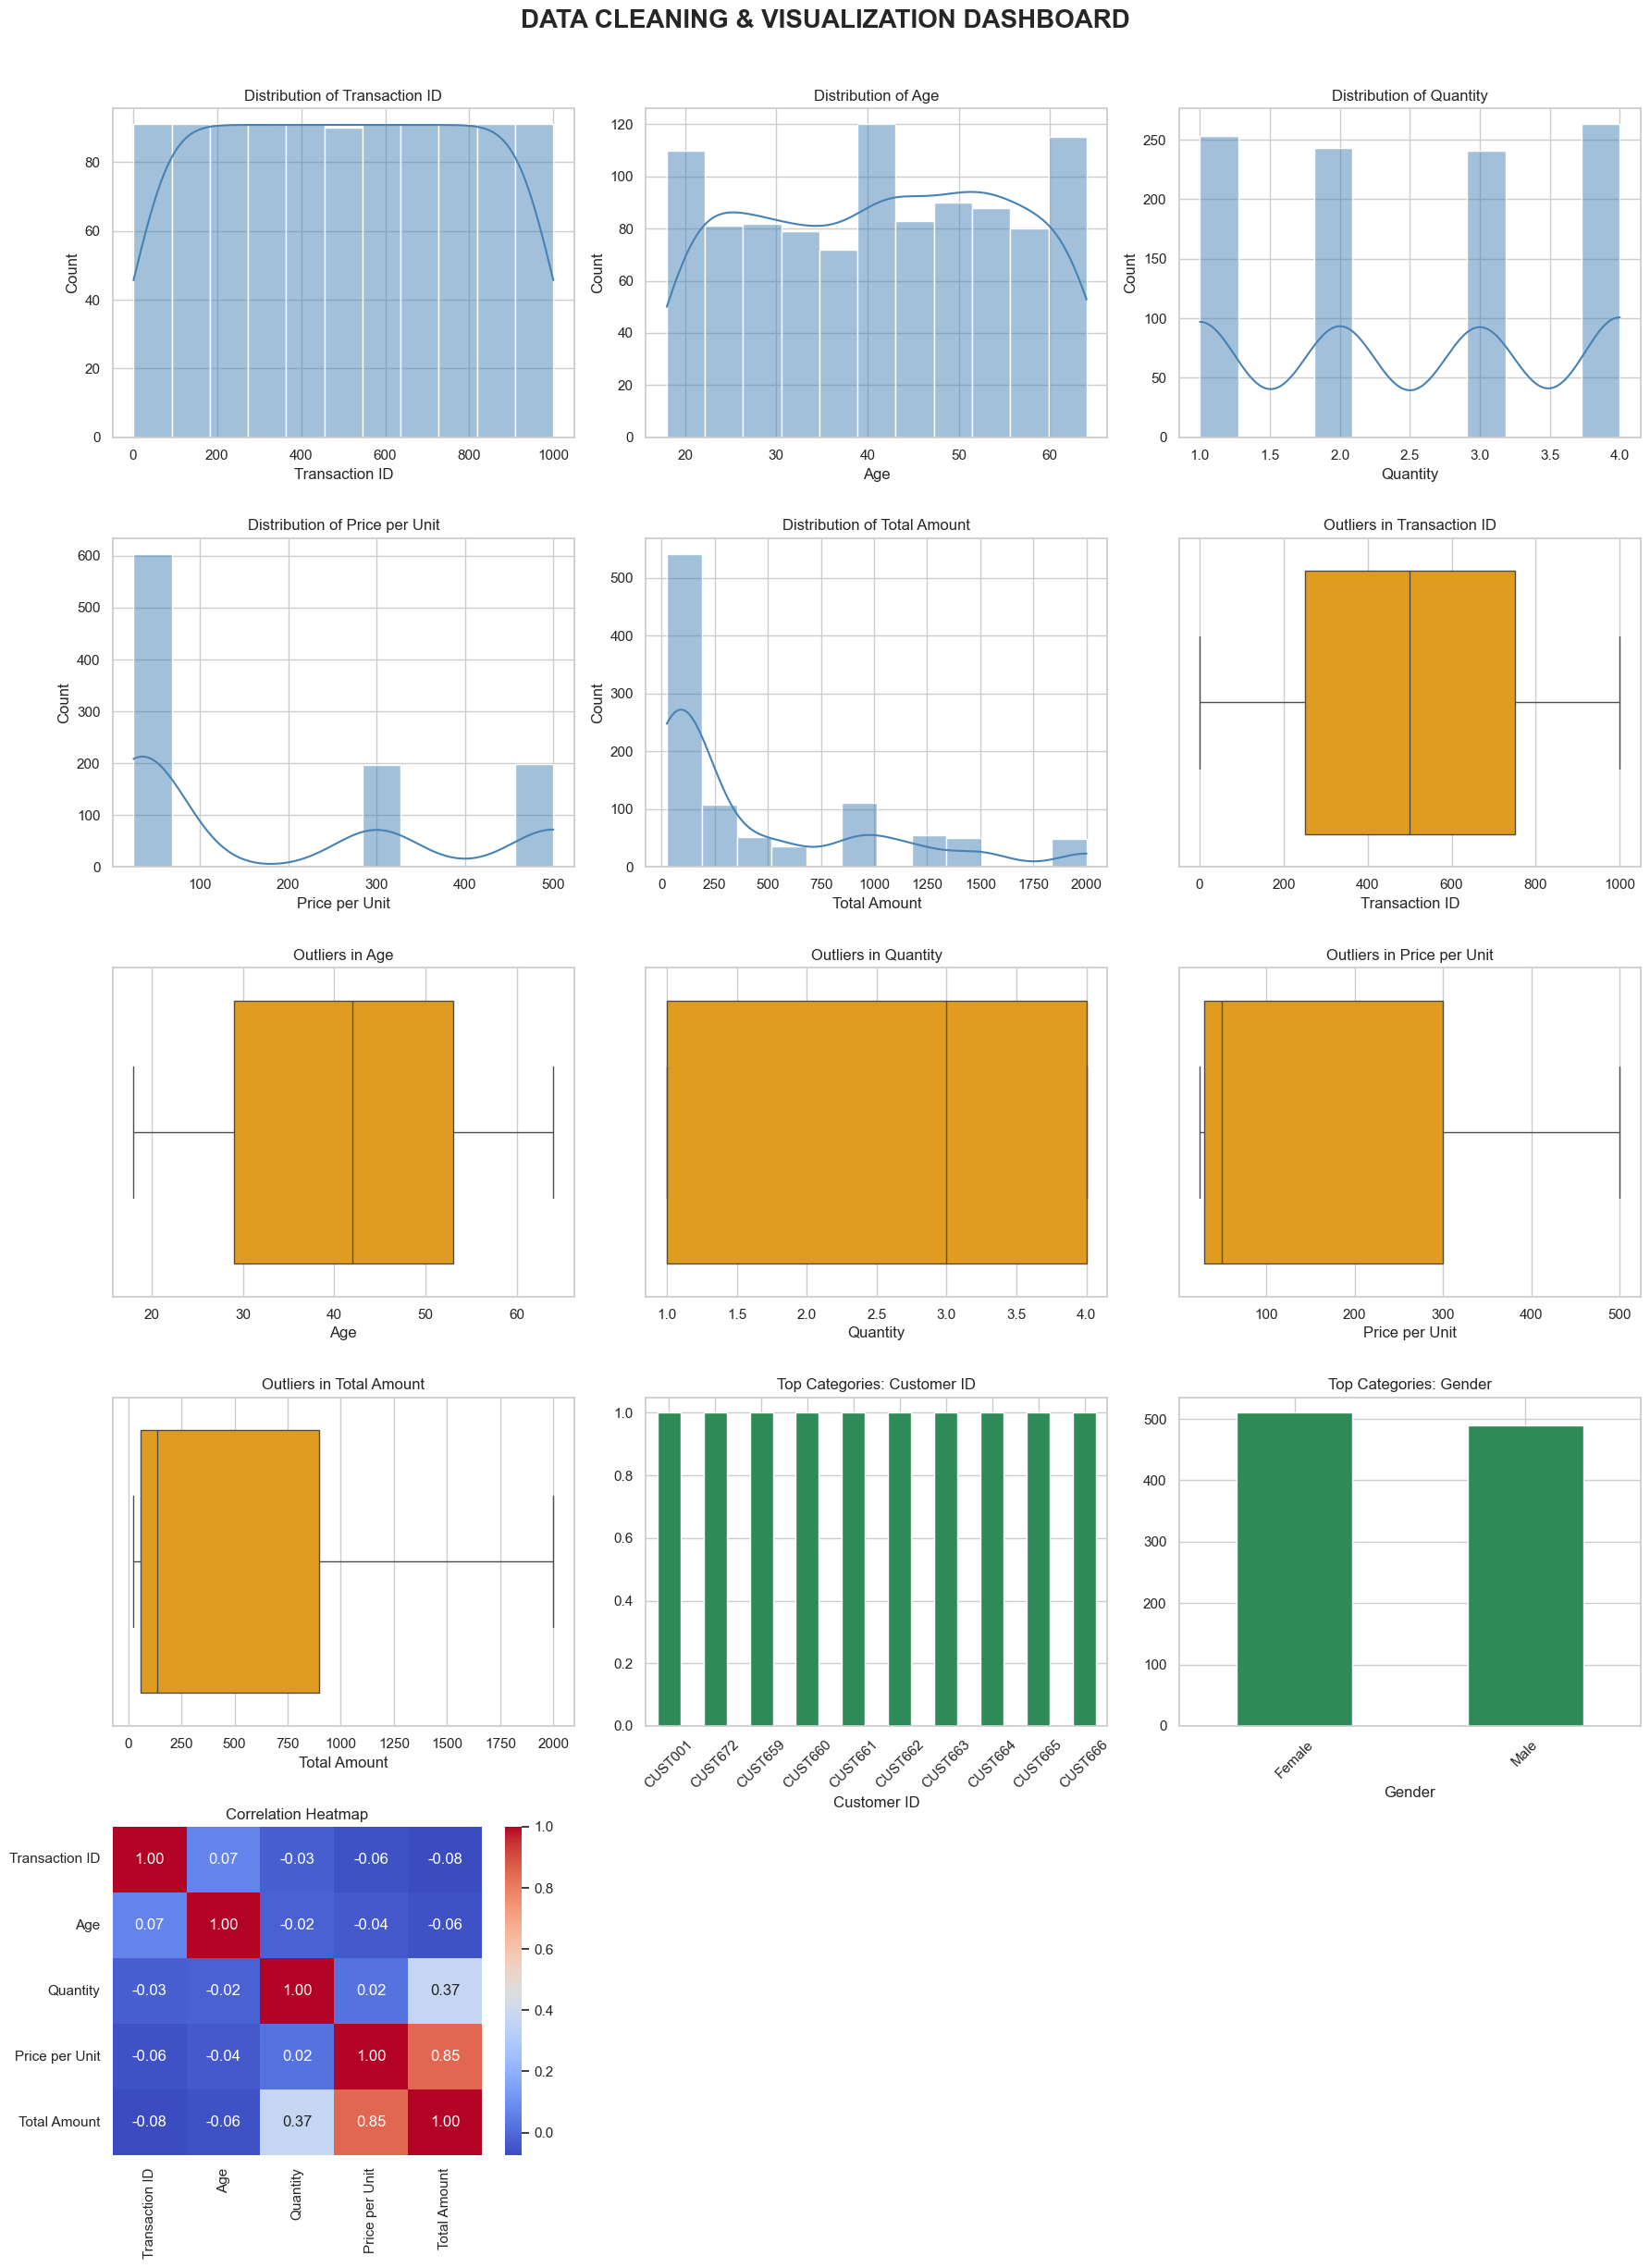

Dashboard saved as all_visualizations.png


In [19]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import math

# Use the cleaned dataset
data = df_clean

# Identify numerical and categorical columns
numeric_cols = data.select_dtypes(include=np.number).columns.tolist()
categorical_cols = data.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Create a single-page dashboard
total_plots = (
    len(numeric_cols) * 2
    + min(len(categorical_cols), 2)
    + 1
)

cols = 3
rows = math.ceil(total_plots / cols)

fig, axes = plt.subplots(
    rows, cols, figsize=(18, 5 * rows)
)
axes = np.array(axes).flatten()

plot_index = 0

# 1. Numerical distributions
for column in numeric_cols:
    sns.histplot(
        data=data, x=column, kde=True,
        ax=axes[plot_index], color="steelblue"
    )
    axes[plot_index].set_title(f"Distribution of {column}")
    plot_index += 1

# 2. Outlier detection using box plots
for column in numeric_cols:
    sns.boxplot(
        data=data, x=column,
        ax=axes[plot_index], color="orange"
    )
    axes[plot_index].set_title(f"Outliers in {column}")
    plot_index += 1

# 3. Categorical data counts
for column in categorical_cols[:2]:
    counts = data[column].value_counts().head(10)
    counts.plot(
        kind="bar", ax=axes[plot_index],
        color="seagreen"
    )
    axes[plot_index].set_title(f"Top Categories: {column}")
    axes[plot_index].tick_params(axis="x", rotation=45)
    plot_index += 1

# 4. Correlation heatmap
if len(numeric_cols) >= 2:
    correlation = data[numeric_cols].corr()
    sns.heatmap(
        correlation, annot=True, cmap="coolwarm",
        fmt=".2f", ax=axes[plot_index]
    )
    axes[plot_index].set_title("Correlation Heatmap")
else:
    axes[plot_index].text(
        0.5, 0.5, "Not enough numerical columns",
        ha="center", va="center"
    )
    axes[plot_index].set_title("Correlation Heatmap")

plot_index += 1

# Hide unused panels
for i in range(plot_index, len(axes)):
    axes[i].set_visible(False)

fig.suptitle(
    "DATA CLEANING & VISUALIZATION DASHBOARD",
    fontsize=20, fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.97])

# Save the complete dashboard as one image
plt.savefig(
    "all_visualizations.png",
    dpi=200, bbox_inches="tight"
)

plt.show()

print("Dashboard saved as all_visualizations.png")
